# 07 · Train a classical pixel classifier

**Level:** intermediate · **Time:** 75–100 minutes · **Runs:** offline, CPU; small random forests

**Prerequisites:** array shapes, image filtering, and IoU from lessons 01–06.
No previously saved notebook output is required.

**You will learn to:** split whole images before training; transform pixels into feature
vectors; sample training pixels; compare RGB with multiscale features; select a model on
validation images; evaluate held-out images; diagnose a controlled domain shift.

The learner sees colors and local textures, not named objects. Our synthetic labels are
deliberately correlated with color, so high scores do not demonstrate general shape recognition.


In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "learning" / "data.py").is_file()), None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the complete ImageSegmentationPractical folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 3.5), "image.cmap": "gray",
                     "axes.spines.top": False, "axes.spines.right": False})
print("Project:", PROJECT_ROOT.name)


Project: ImageSegmentationPractical


Images: (30, 64, 64, 3) float32 Masks: (30, 64, 64) uint8


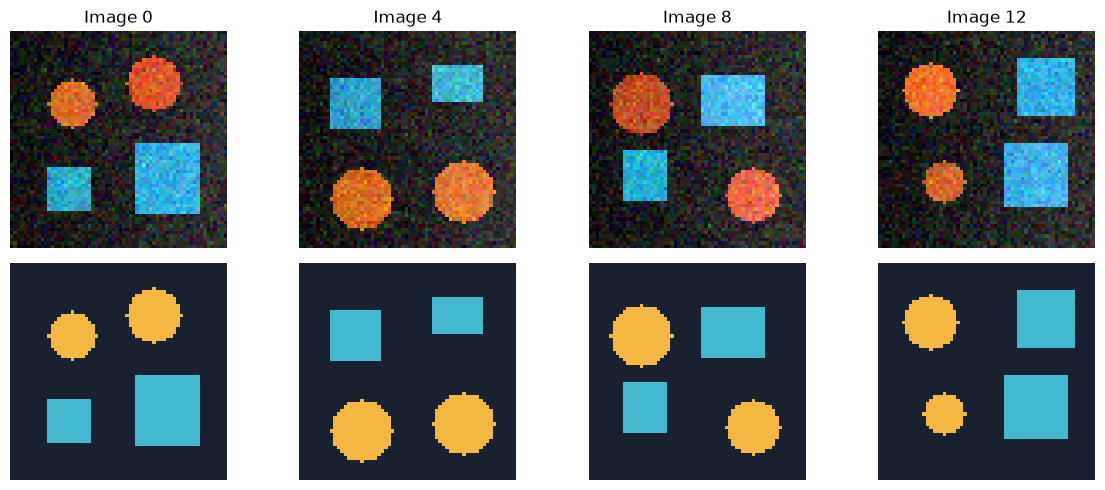

In [2]:
import pandas as pd
from scipy import ndimage as ndi
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix
from learning.data import make_dataset, palette_mask, show_triplet

images, masks = make_dataset(n=30, size=64, seed=700, noise=0.08)
print('Images:', images.shape, images.dtype, 'Masks:', masks.shape, masks.dtype)
fig, axes = plt.subplots(2, 4, figsize=(12, 5))
for col, idx in enumerate([0, 4, 8, 12]):
    axes[0, col].imshow(images[idx]); axes[0, col].set_title(f'Image {idx}')
    axes[1, col].imshow(palette_mask(masks[idx]))
for ax in axes.ravel(): ax.axis('off')
plt.tight_layout(); plt.show()


## Step 1 — Split images before flattening pixels

Adjacent pixels share texture, illumination, and sometimes almost the same feature vector.
Randomly splitting all pixels mixes each scene into training and evaluation and gives an
optimistic estimate for new scenes. We split **image IDs** first, then sample pixels only
within training images. For repeated patients, videos, or tiles from one slide, split the
higher-level group instead.

We reserve 18 training, 6 validation, and 6 test images. These splits are intentionally small
for speed, not adequate for a production claim.


In [3]:
ids = np.random.default_rng(42).permutation(len(images))
train_ids, val_ids, test_ids = ids[:18], ids[18:24], ids[24:]
assert not (set(train_ids) & set(val_ids) or set(train_ids) & set(test_ids) or set(val_ids) & set(test_ids))
print('Train IDs:', train_ids.tolist())
print('Validation IDs:', val_ids.tolist())
print('Test IDs: reserved until the model choice is frozen')
print('Training class fractions:', np.bincount(masks[train_ids].ravel(), minlength=3) / masks[train_ids].size)


Train IDs: [29, 16, 7, 25, 24, 22, 5, 21, 26, 10, 19, 20, 9, 6, 18, 3, 0, 15]
Validation IDs: [17, 23, 12, 11, 14, 28]
Test IDs: reserved until the model choice is frozen
Training class fractions: [0.77761502 0.09326172 0.12912326]


## Step 2 — Represent one pixel as a feature vector

The RGB baseline uses three numbers per pixel. The multiscale version adds, for each color
channel, Gaussian-smoothed intensity, local standard deviation, and gradient magnitude at
several spatial scales. A larger sigma sees more neighborhood context but can blur small objects.

These filters have fixed parameters and learn nothing from the dataset. Computing them on a
validation image is allowed. Any learned normalization, PCA, or feature selection must instead
be fitted only on training data. We omit coordinates to avoid teaching a fixed-position shortcut.


Feature volume (height, width, features): (64, 64, 21)
Classifier input (pixels, features): (4096, 21)


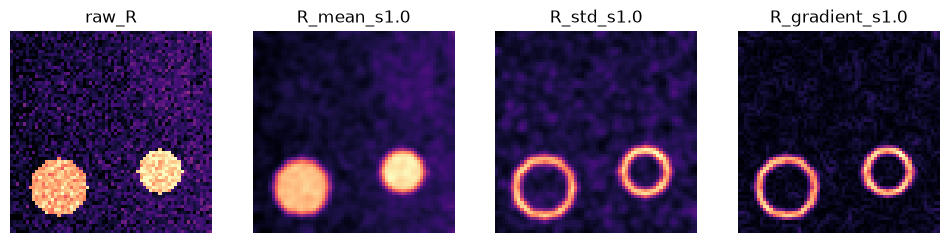

In [4]:
def pixel_features(image, multiscale=True, sigmas=(1.0, 3.0)):
    image = np.asarray(image, dtype=np.float32)
    planes = [image[..., c] for c in range(3)]
    names = [f'raw_{name}' for name in 'RGB']
    if multiscale:
        for sigma in sigmas:
            for c, channel in enumerate('RGB'):
                a = image[..., c]
                smooth = ndi.gaussian_filter(a, sigma=sigma, mode='reflect')
                local_second = ndi.gaussian_filter(a*a, sigma=sigma, mode='reflect')
                local_std = np.sqrt(np.maximum(local_second-smooth*smooth, 0))
                gradient = ndi.gaussian_gradient_magnitude(a, sigma=sigma, mode='reflect')
                planes.extend([smooth, local_std, gradient])
                names.extend([f'{channel}_mean_s{sigma}', f'{channel}_std_s{sigma}',
                              f'{channel}_gradient_s{sigma}'])
    features = np.stack(planes, axis=-1).astype(np.float32)
    assert features.shape[:2] == image.shape[:2] and np.isfinite(features).all()
    return features, names

example_features, feature_names = pixel_features(images[train_ids[0]])
print('Feature volume (height, width, features):', example_features.shape)
print('Classifier input (pixels, features):', example_features.reshape(-1, example_features.shape[-1]).shape)
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, j in zip(axes, [0, 3, 4, 5]):
    ax.imshow(example_features[..., j], cmap='magma'); ax.set_title(feature_names[j]); ax.axis('off')
plt.show()


## Step 3 — Sample only training pixels

We cap examples at 250 pixels per class per training image. This reduces memory and makes
minority classes visible to the learner. Evaluation still uses **every pixel** of each held-out
image. Balancing the training sample changes the effective class prior; the resulting forest
probabilities should not automatically be interpreted as calibrated deployment probabilities.

Trees split on feature thresholds and do not require standardization. If replacing the forest
with logistic regression or an SVM, use a `Pipeline(StandardScaler(), model)` fitted on the
sampled training rows; never fit the scaler on validation or test pixels.


In [5]:
def sampled_training_rows(image_ids, multiscale=True, per_class=250, seed=10):
    rng = np.random.default_rng(seed)
    x_parts, y_parts = [], []
    for idx in image_ids:
        feature_map, names = pixel_features(images[idx], multiscale=multiscale)
        x = feature_map.reshape(-1, feature_map.shape[-1])
        y = masks[idx].ravel()
        selected = []
        for class_id in range(3):
            available = np.flatnonzero(y == class_id)
            selected.extend(rng.choice(available, size=min(per_class, len(available)), replace=False))
        selected = np.asarray(selected, dtype=int)
        x_parts.append(x[selected]); y_parts.append(y[selected])
    return np.concatenate(x_parts), np.concatenate(y_parts), names

x_rgb, y_train, rgb_names = sampled_training_rows(train_ids, multiscale=False)
x_multi, y_multi, feature_names = sampled_training_rows(train_ids, multiscale=True)
assert np.array_equal(y_train, y_multi)  # same sampled positions for a fair feature comparison
print('RGB:', x_rgb.shape, 'Multiscale:', x_multi.shape)
print('Sampled class counts:', np.bincount(y_train, minlength=3))
print(f'Multiscale training features: {x_multi.nbytes/1e6:.2f} MB')


RGB: (13500, 3) Multiscale: (13500, 21)
Sampled class counts: [4500 4500 4500]
Multiscale training features: 1.13 MB


## Step 4 — Establish a deliberately simple baseline

First evaluate a background-only predictor. Then train a random forest on RGB. A forest
averages the predictions of several randomized decision trees. More trees cost computation;
maximum depth and minimum leaf size constrain the complexity of each tree.

The metric below pools the confusion counts over the selected images and averages per-class
IoUs equally, including background. It also reports mean IoU over the two foreground classes.


In [6]:
def predict_image(model, image, multiscale):
    f, _ = pixel_features(image, multiscale=multiscale)
    return model.predict(f.reshape(-1, f.shape[-1])).reshape(image.shape[:2])

def evaluate_model(model, image_ids, multiscale):
    cm = np.zeros((3, 3), dtype=np.int64)
    predictions = []
    for idx in image_ids:
        pred = predict_image(model, images[idx], multiscale)
        predictions.append(pred)
        cm += confusion_matrix(masks[idx].ravel(), pred.ravel(), labels=[0, 1, 2])
    tp = np.diag(cm).astype(float)
    union = cm.sum(0)+cm.sum(1)-tp
    ious = np.divide(tp, union, out=np.full(3, np.nan), where=union > 0)
    report = {'background_IoU': ious[0], 'disk_IoU': ious[1], 'rectangle_IoU': ious[2],
              'macro_IoU': np.nanmean(ious), 'foreground_macro_IoU': np.nanmean(ious[1:])}
    return report, predictions

dummy = DummyClassifier(strategy='constant', constant=0).fit(x_rgb, y_train)
rgb_model = RandomForestClassifier(n_estimators=40, max_depth=10,
                                  min_samples_leaf=3, random_state=42, n_jobs=1)
rgb_model.fit(x_rgb, y_train)
baseline_report, _ = evaluate_model(dummy, val_ids, False)
rgb_report, rgb_predictions = evaluate_model(rgb_model, val_ids, False)
print(pd.DataFrame([baseline_report, rgb_report], index=['background only', 'RGB forest']).round(3))


                 background_IoU  disk_IoU  rectangle_IoU  macro_IoU  \
background only           0.792       0.0            0.0      0.264   
RGB forest                1.000       1.0            1.0      1.000   

                 foreground_macro_IoU  
background only                   0.0  
RGB forest                        1.0  


## Step 5 — Compare candidates using validation only

Add neighborhood features, then change tree depth. Keep the image split, sampled positions,
random seed, and evaluation metric fixed so the comparison has a clear interpretation.
Multiscale features are not guaranteed to win: this dataset may be solved mostly by color.

We choose the highest validation class-macro IoU from three candidates, then freeze the
candidate. If validation scores tie, the first candidate wins by our declared tie rule.


In [7]:
candidates = [('RGB depth 10', rgb_model, False, rgb_report)]
for depth in [6, 12]:
    model = RandomForestClassifier(n_estimators=40, max_depth=depth,
                                   min_samples_leaf=3, random_state=42, n_jobs=1)
    model.fit(x_multi, y_train)
    report, _ = evaluate_model(model, val_ids, True)
    candidates.append((f'Multiscale depth {depth}', model, True, report))
validation_results = pd.DataFrame([{'candidate': name, **report}
                                   for name, _, _, report in candidates])
print(validation_results.round(4).to_string(index=False))
best_index = int(validation_results.macro_IoU.argmax())
frozen_name, frozen_model, frozen_multiscale, _ = candidates[best_index]
print('Frozen candidate:', frozen_name)


          candidate  background_IoU  disk_IoU  rectangle_IoU  macro_IoU  foreground_macro_IoU
       RGB depth 10             1.0       1.0            1.0        1.0                   1.0
 Multiscale depth 6             1.0       1.0            1.0        1.0                   1.0
Multiscale depth 12             1.0       1.0            1.0        1.0                   1.0
Frozen candidate: RGB depth 10


## Step 6 — Evaluate the frozen model once

The test score estimates performance on new images from this same synthetic generator.
Do not respond to a disappointing result by choosing another candidate on test scores.
That would turn the test set into another validation set.


Final held-out report: RGB depth 10
background_IoU          0.9999
disk_IoU                0.9996
rectangle_IoU           1.0000
macro_IoU               0.9998
foreground_macro_IoU    0.9998
dtype: float64


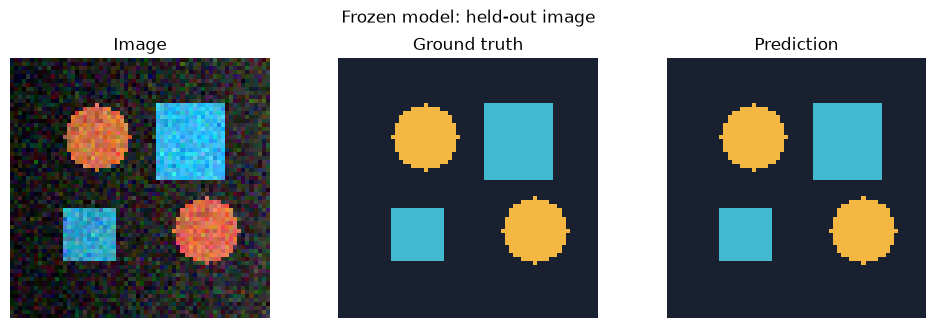

In [8]:
test_report, test_predictions = evaluate_model(frozen_model, test_ids, frozen_multiscale)
print('Final held-out report:', frozen_name)
print(pd.Series(test_report).round(4))
show_triplet(images[test_ids[0]], masks[test_ids[0]], test_predictions[0],
             title='Frozen model: held-out image')
plt.show()


## Step 7 — Inspect features and uncertainty cautiously

A feature-importance chart can reveal reliance on color. The forest's impurity-based importance
is an internal diagnostic, not proof that a feature causes correct predictions; correlated
features share importance and the ranking can be biased.

Predictive entropy is high when the forest distributes probability across several classes.
Low entropy is not a guarantee of correctness, especially after a distribution shift.


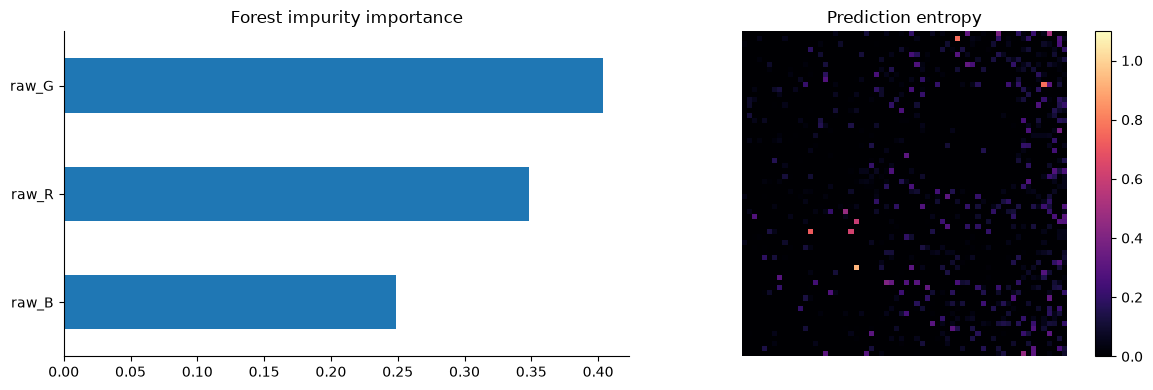

In [9]:
chosen_names = feature_names if frozen_multiscale else rgb_names
importance = pd.Series(frozen_model.feature_importances_, index=chosen_names).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
importance.tail(10).plot.barh(ax=axes[0]); axes[0].set_title('Forest impurity importance')
features, _ = pixel_features(images[test_ids[0]], multiscale=frozen_multiscale)
probabilities = frozen_model.predict_proba(features.reshape(-1, features.shape[-1]))
entropy = -(probabilities*np.log(np.maximum(probabilities, 1e-12))).sum(axis=1)
entropy = entropy.reshape(images.shape[1:3])
im = axes[1].imshow(entropy, cmap='magma', vmin=0, vmax=np.log(3))
axes[1].set_title('Prediction entropy'); axes[1].axis('off'); fig.colorbar(im, ax=axes[1])
plt.tight_layout(); plt.show()


## Step 8 — Make a controlled domain shift

We reverse the intensity scale of fresh images while keeping their geometry and labels.
This simulates a deliberately severe change in image appearance. A color-based forest can
confidently fail. The shift is a diagnostic challenge separate from the original final test;
it is not evidence of performance on any particular real camera or microscope.

A remedy needs labeled data representative of the intended use, plus a new independent
validation/test protocol. Applying a transformation because it improves these challenge labels
and then reporting the same images as an untouched test would be leakage.


Fresh ordinary images: macro IoU 1.000
Same geometry, inverted appearance: macro IoU 0.000


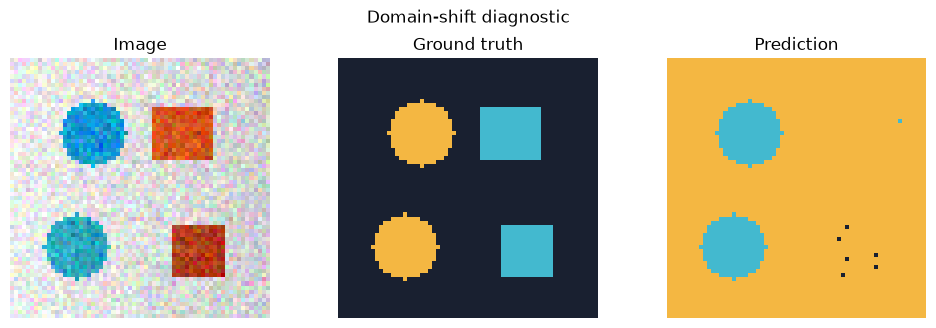

In [10]:
challenge_images, challenge_masks = make_dataset(n=6, size=64, seed=1700, noise=0.08)
shifted_images = 1.0-challenge_images

def evaluate_external(batch, targets):
    cm = np.zeros((3, 3), dtype=np.int64)
    preds = []
    for image, target in zip(batch, targets):
        pred = predict_image(frozen_model, image, frozen_multiscale)
        preds.append(pred)
        cm += confusion_matrix(target.ravel(), pred.ravel(), labels=[0, 1, 2])
    tp = np.diag(cm).astype(float); union = cm.sum(0)+cm.sum(1)-tp
    ious = np.divide(tp, union, out=np.full(3, np.nan), where=union > 0)
    return float(np.nanmean(ious)), preds

ordinary_iou, _ = evaluate_external(challenge_images, challenge_masks)
shifted_iou, shifted_predictions = evaluate_external(shifted_images, challenge_masks)
print(f'Fresh ordinary images: macro IoU {ordinary_iou:.3f}')
print(f'Same geometry, inverted appearance: macro IoU {shifted_iou:.3f}')
show_triplet(shifted_images[0], challenge_masks[0], shifted_predictions[0],
             title='Domain-shift diagnostic')
plt.show()


## Your experiments

**Exercise 1 — Budget the annotations.** Compare 25, 100, and 250 labeled pixels per class
per training image. Hold forest settings fixed and report validation macro IoU and the number
of sampled rows. Leave the final test set out of this experiment.

<details><summary>Worked solution</summary>

```python
rows = []
for budget in [25, 100, 250]:
    x, y, _ = sampled_training_rows(train_ids, True, per_class=budget)
    model = RandomForestClassifier(n_estimators=40, max_depth=12,
        min_samples_leaf=3, random_state=42, n_jobs=1).fit(x, y)
    report, _ = evaluate_model(model, val_ids, True)
    rows.append({'pixels_per_class': budget, 'training_rows': len(y), **report})
print(pd.DataFrame(rows))
```

A larger sample may give only a small gain because nearby pixels are redundant. More
independent images can add information that more pixels from the same images cannot.

</details>

**Exercise 2 — Change the feature scales.** Add sigma=6 to the feature function. Retrain
a multiscale candidate and compare it on validation. Why might tiny structures suffer?

<details><summary>Worked solution</summary>

Change the default to `sigmas=(1.0, 3.0, 6.0)` and rerun feature extraction, sampling, and
candidate training before making predictions. Each scale adds 9 features. The wider filters
mix neighborhoods across object boundaries. A model trained with one feature schema cannot
safely predict using another; names, order, and parameters must match exactly.

</details>

**Exercise 3 — Design a leakage-safe adaptation study.** You have labeled images from a
new camera. Specify the training, validation, and test roles before changing the forest.

<details><summary>Worked solution</summary>

Group images by scene/acquisition session and split those groups. Use the training portion
for fitting, validation for feature choices and augmentation settings, and the untouched new-camera
test portion for the final report. Keep the previous distribution test as a separate check for
regression. Do not use the entire new-camera set to fit normalization or choose transformations.

</details>


In [11]:
# Your workspace: document the change, prediction, measured validation result, and lesson.
experiment_log = pd.DataFrame(columns=['change', 'prediction', 'validation_macro_IoU', 'observation'])
print(experiment_log)


Empty DataFrame
Columns: [change, prediction, validation_macro_IoU, observation]
Index: []


## Common mistakes and completion checklist

- **Suspiciously perfect validation:** check whether images or related groups cross splits.
- **Prediction shape is wrong:** preserve feature order and reshape using the input height/width.
- **Model misses a class:** inspect sampled label counts and class-specific IoU.
- **Smoothing labels:** labels are discrete IDs; filtering features is different from blurring labels.
- **Interpreting color success as object understanding:** test controlled appearance changes.
- **Oversized RAM use:** sample training rows, reduce image size or scales, and predict in tiles
  with enough overlap for filters when using large images.

- [ ] Split independent images/groups before sampling pixels.
- [ ] Explain each dimension in `(height, width, features)` and `(pixels, features)`.
- [ ] Compare a simple baseline with at least one richer candidate on validation.
- [ ] Evaluate every held-out pixel without balancing the evaluation sample.
- [ ] Freeze the model before the final test and explain its domain-shift limitations.

**Continue:** lesson 08 introduces learned neural features and tensor layouts.

**Primary references:** [scikit-image trainable segmentation example](https://scikit-image.org/docs/stable/auto_examples/segmentation/plot_trainable_segmentation.html),
[RandomForestClassifier API](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html),
[scikit-learn leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html),
[grouped splitting](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html).
